# Two-Stage CAD Pipeline — Brain Tumor MRI
**Segmentasi (Attention U-Net) -> ROI Bridge -> Klasifikasi (EfficientNet-B4 + ResNet-50 Ensemble)**
Dataset: `indk214/brain-tumor-dataset-segmentation-and-classification`

| Tahap | Nama | Fungsi |
|---|---|---|
| 0 | Install Packages (+ Mount Drive) | Instal library; mount Google Drive jika dataset ada di Drive |
| 1 | Imports & Configuration | Import, seed, path, hyperparameter, konstanta bersama |
| 2 | Data Loading & Stratified Split | Pairing image-mask (Segmentation) dan listing Training/Testing (classification); split stratified |
| 3 | Data Visualization (EDA) | Distribusi kelas, sampel, statistik ukuran/intensitas, luas mask, mask kosong, deteksi duplikat/kebocoran |
| 4 | Transforms & Augmentation | Augmentasi gabungan image+mask (segmentasi) dan augmentasi klasifikasi |
| 5 | Data Loaders (Stage 1) | DataLoader segmentasi |
| 6 | Stage 1: Model Architecture | Attention U-Net |
| 7 | Stage 1: Loss & Training Setup | BCE+Dice, metrik Dice/IoU, optimizer, scheduler, early stopping |
| 8 | Stage 1: Training Loop & Curves | Training segmentasi, kurva, evaluasi test, cek visual |
| 9 | The Bridge: ROI Masking & Cropping | Freeze Stage 1, ekstrak ROI dari mask **prediksi**, cache ROI |
| 10 | Stage 2: Data Loaders (Balancer) | `WeightedRandomSampler` pada ROI |
| 11 | Stage 2: Model Architecture | EffNetB4Classifier & ResNet50Classifier (GAP -> Dropout -> Dense(4)) |
| 12 | Loss Function & Training Setup | Focal Loss + class weights, AdamW (LR beda backbone vs head), ReduceLROnPlateau |
| 13 | Training Loop (3 fase) | Freeze total -> unfreeze sebagian -> unfreeze penuh, early stopping, checkpoint |
| 14 | Training Curves | Loss, akurasi, Macro-F1 kedua model |
| 15 | Evaluasi Individual & Ensemble | Bobot ensemble optimal dicari di validation, diterapkan ke test |
| 16 | Confusion Matrix & ROC | CM 4x4 dan ROC one-vs-rest |
| 17 | Prediction Visualization & Error Analysis | Contoh benar vs salah, akurasi per kelas, hubungan error dengan fallback ROI |
| 18 | Grad-CAM | Heatmap fokus kedua model pada ROI |
| 19 | End-to-End Inference | `predict_end_to_end` + `scan_folder` (untuk dataset lain) |
| 20 | Simpan Artefak & Deployment Guide | Model, config, histori, prediksi, `cad_inference.py`, panduan, zip |

Sel bertanda `# @@SHARED:...` otomatis dipakai Tahap 20 untuk membuat script deployment mandiri, jadi **jangan ubah marker-nya**.

## Tahap 0 — Install Required Packages (+ Mount Google Drive)

In [1]:
import sys, subprocess
PKGS = ["torch", "torchvision", "scikit-learn", "matplotlib", "opencv-python-headless", "pandas", "tqdm"]
subprocess.run([sys.executable, "-m", "pip", "install", "-q", *PKGS], check=False)

USE_DRIVE = True        # True jika dataset/artefak mau disimpan di Google Drive (Colab)
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=True)

Mounted at /content/drive


## Tahap 1 — Imports & Configuration

In [18]:
import os, re, json, random, time, shutil
from pathlib import Path
from collections import Counter
import numpy as np, cv2, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, f1_score, roc_curve, auc
from sklearn.preprocessing import label_binarize
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
import torchvision
from torchvision import transforms as T

# ---------- Konfigurasi ----------
SEED        = 42

# 1. Path diubah mengarah ke folder dataset di dalam final_project_dl
DATA_ROOT   = "/content/drive/MyDrive/final_project_dl/cad-brain-tumor-dataset"

# Pastikan USE_DRIVE bernilai True agar Colab tahu kita pakai Google Drive
USE_DRIVE   = True

if USE_DRIVE:
    # 2. Path output diarahkan ke folder outputs_v2 yang sudah ada di Drive-mu
    WORK_DIR = Path("/content/drive/MyDrive/final_project_dl/outputs_vbaru")
else:
    WORK_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path("./outputs")
WORK_DIR.mkdir(parents=True, exist_ok=True)

SEG_BS, SEG_EPOCHS, SEG_LR = 16, 60, 3e-4
CLS_BS = 24
PATIENCE_SEG, PATIENCE_CLS = 8, 6
CLS_VAL_FRAC  = 0.15            # Train 85% / Val 15%
NUM_WORKERS   = 0
FILTER_LEAK   = True            # buang duplikat/kebocoran (hasil EDA tahap 3)
TRAIN_SEG, TRAIN_CLS = True, True   # False = load checkpoint yang sudah ada

SEG_CKPT  = WORK_DIR / "best_seg.pt"
CLS_CKPT  = {"effnet_b4": WORK_DIR / "best_effnet_b4.pt", "resnet50": WORK_DIR / "best_resnet50.pt"}
ROI_CACHE = WORK_DIR / "roi_cache"

def seed_everything(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_everything()

In [3]:
# @@SHARED:consts
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
CLASSES = ["glioma", "meningioma", "notumor", "pituitary"]
SEG_SIZE, CLS_SIZE = 256, 256
SEG_THR, ROI_MARGIN, MIN_AREA = 0.5, 0.10, 0.002
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"

def read_gray(path):
    im = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if im is None: raise IOError(f"Gagal baca: {path}")
    return im

In [4]:
print("Device:", DEVICE, "| AMP:", USE_AMP)

Device: cuda | AMP: True


## Tahap 2 — Data Loading & Stratified Split

In [5]:
def find_data_root():
    if DATA_ROOT: return Path(DATA_ROOT)
    for base in ["/kaggle/input", "/content", ".", ".."]:
        if not os.path.exists(base): continue
        for dp, dns, _ in os.walk(base):
            low = {d.lower() for d in dns}
            if "segmentation" in low and "classification" in low: return Path(dp)
            if dp.count(os.sep) - str(base).count(os.sep) > 4: dns[:] = []
    raise FileNotFoundError("Folder DATASET tidak ketemu. Isi DATA_ROOT manual.")

ROOT    = find_data_root()
SEG_DIR = next(p for p in ROOT.iterdir() if p.name.lower() == "segmentation")
CLS_DIR = next(p for p in ROOT.iterdir() if p.name.lower() == "classification")
print("ROOT:", ROOT)

def tree(p, depth=0, max_depth=3, max_files=3):
    files = [f for f in p.iterdir() if f.is_file()]
    print("  " * depth + f"[{p.name}] files={len(files)} e.g. {[f.name for f in files[:max_files]]}")
    if depth < max_depth:
        for d in sorted(x for x in p.iterdir() if x.is_dir()): tree(d, depth + 1, max_depth, max_files)
print("--- Segmentation ---");   tree(SEG_DIR)
print("--- Classification ---"); tree(CLS_DIR, max_depth=2, max_files=2)

ROOT: /content/drive/MyDrive/final_project_dl/cad-brain-tumor-dataset
--- Segmentation ---
[Segmentation] files=0 e.g. []
  [Glioma] files=1108 e.g. ['enh_1895.png', 'enh_1895_mask.png', 'enh_1896.png']
  [Meningioma] files=1416 e.g. ['enh_28_mask.png', 'enh_29.png', 'enh_290.png']
  [Pituitary tumor] files=1860 e.g. ['enh_1430.png', 'enh_1430_mask.png', 'enh_1431.png']
--- Classification ---
[classification] files=0 e.g. []
  [Testing] files=0 e.g. []
    [glioma] files=300 e.g. ['enh_Te-glTr_0000.jpg', 'enh_Te-glTr_0001.jpg']
    [meningioma] files=306 e.g. ['enh_Te-meTr_0000.jpg', 'enh_Te-meTr_0001.jpg']
    [notumor] files=405 e.g. ['enh_Te-noTr_0000.jpg', 'enh_Te-noTr_0001.jpg']
    [pituitary] files=300 e.g. ['enh_Te-piTr_0000.jpg', 'enh_Te-piTr_0001.jpg']
  [Training] files=0 e.g. []
    [glioma] files=1321 e.g. ['enh_Tr-gl_0321.jpg', 'enh_Tr-gl_0322.jpg']
    [meningioma] files=1339 e.g. ['enh_Tr-me_0339.jpg', 'enh_Tr-me_0340.jpg']
    [notumor] files=1595 e.g. ['enh_Tr-no_0595

**Pairing image <-> mask (Segmentation).** File dianggap *mask* jika nama file/foldernya mengandung `mask / seg / label / gt`; pasangan dicocokkan lewat nama dasar. Jika `paired` = 0 atau janggal, lihat output `tree` di atas lalu sesuaikan `is_mask_file` / `pair_key`.

In [6]:
MASK_TOKENS = {"mask", "masks", "seg", "segmentation", "label", "labels", "gt", "groundtruth", "annotation"}
def _tokens(s): return [t for t in re.split(r"[_\-\s.]+", s.lower()) if t]
def is_mask_file(rel: Path):
    in_dir = any(set(_tokens(part)) & MASK_TOKENS for part in rel.parts[:-1])
    return in_dir or bool(set(_tokens(rel.stem)) & MASK_TOKENS)
def pair_key(rel: Path):
    return "_".join(t for t in _tokens(rel.stem) if t not in MASK_TOKENS)

def build_seg_df(seg_dir):
    rows = []
    for cdir in sorted(d for d in seg_dir.iterdir() if d.is_dir()):
        cname = cdir.name.lower().replace(" tumor", "").replace(" ", "")      # "Pituitary tumor" -> "pituitary"
        imgs, masks = {}, {}
        for f in cdir.rglob("*"):
            if f.suffix.lower() not in IMG_EXT: continue
            rel = f.relative_to(cdir)
            (masks if is_mask_file(rel) else imgs)[pair_key(rel)] = f
        paired = [(imgs[k], masks[k]) for k in imgs if k in masks]
        rows += [dict(image=str(a), mask=str(b), label=cname) for a, b in paired]
        print(f"{cdir.name:>16}: images={len(imgs)} masks={len(masks)} paired={len(paired)}")
    df = pd.DataFrame(rows)
    assert len(df) > 0, "Tidak ada pasangan image-mask. Cek struktur di atas."
    return df

def split_seg(df):
    tr, tmp = train_test_split(df, test_size=0.2, stratify=df.label, random_state=SEED)
    va, te  = train_test_split(tmp, test_size=0.5, stratify=tmp.label, random_state=SEED)
    return [d.reset_index(drop=True) for d in (tr, va, te)]

def list_cls_split(split_name):
    sdir = next(p for p in CLS_DIR.iterdir() if p.name.lower() == split_name.lower())
    rows = []
    for cdir in sorted(d for d in sdir.iterdir() if d.is_dir()):
        lbl = cdir.name.lower()
        if lbl in CLASSES:
            rows += [dict(image=str(f), label=lbl) for f in sorted(cdir.rglob("*")) if f.suffix.lower() in IMG_EXT]
    return pd.DataFrame(rows)

seg_df = build_seg_df(SEG_DIR)
seg_tr, seg_va, seg_te = split_seg(seg_df)

cls_all = list_cls_split("Training")
cls_te  = list_cls_split("Testing").reset_index(drop=True)
cls_tr, cls_va = train_test_split(cls_all, test_size=CLS_VAL_FRAC, stratify=cls_all.label, random_state=SEED)
cls_tr, cls_va = cls_tr.reset_index(drop=True), cls_va.reset_index(drop=True)
print(f"SEG  train/val/test = {len(seg_tr)}/{len(seg_va)}/{len(seg_te)}")
print(f"CLS  train/val/test = {len(cls_tr)}/{len(cls_va)}/{len(cls_te)}")

          Glioma: images=554 masks=554 paired=554
      Meningioma: images=708 masks=708 paired=708
 Pituitary tumor: images=930 masks=930 paired=930
SEG  train/val/test = 1753/219/220
CLS  train/val/test = 4855/857/1311


## Tahap 3 — Data Visualization (EDA)

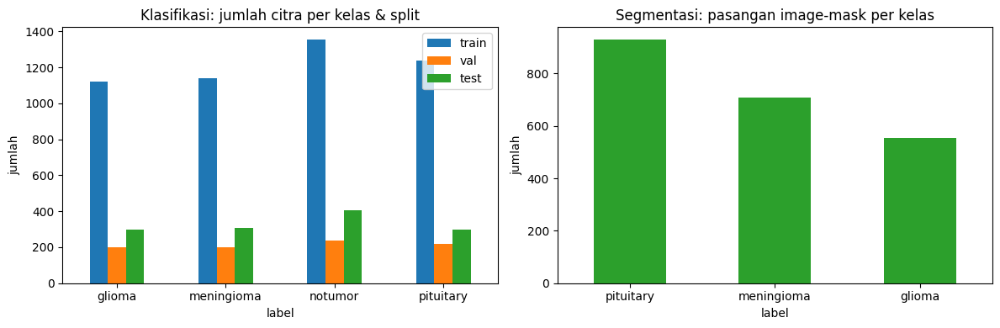

            train  val  test
label                       
glioma       1123  198   300
meningioma   1138  201   306
notumor      1356  239   405
pituitary    1238  219   300

Imbalance ratio (train, max/min): 1.21


In [7]:
# 3a. Distribusi kelas
dist = pd.DataFrame({"train": cls_tr.label.value_counts(), "val": cls_va.label.value_counts(),
                     "test": cls_te.label.value_counts()}).reindex(CLASSES)
seg_dist = seg_df.label.value_counts()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
dist.plot.bar(ax=ax[0], rot=0, title="Klasifikasi: jumlah citra per kelas & split")
seg_dist.plot.bar(ax=ax[1], rot=0, color="tab:green", title="Segmentasi: pasangan image-mask per kelas")
for a in ax: a.set_ylabel("jumlah")
plt.tight_layout(); plt.show()
print(dist); print("\nImbalance ratio (train, max/min):", round(dist.train.max() / dist.train.min(), 2))

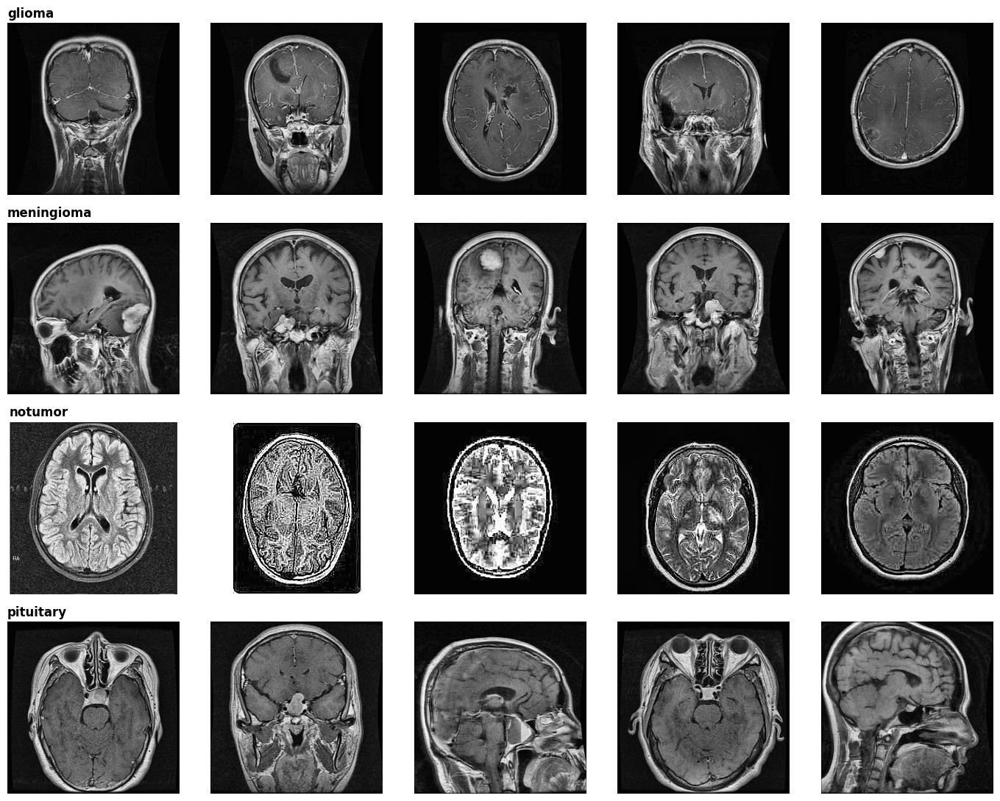

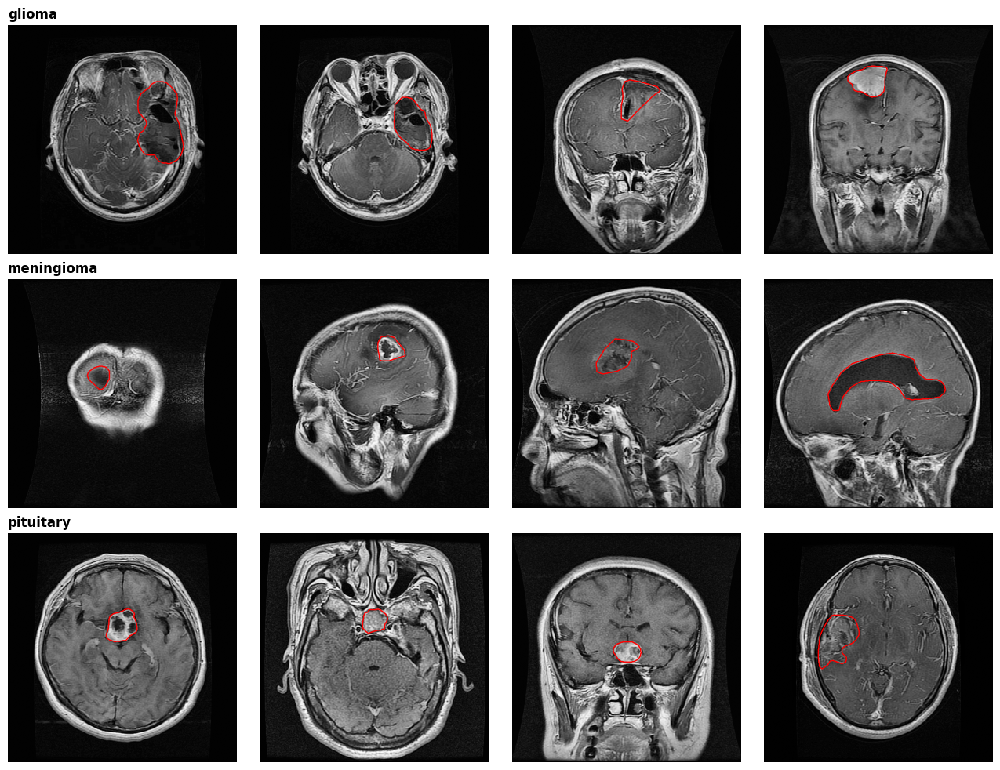

In [8]:
# 3b. Contoh citra klasifikasi per kelas
fig, ax = plt.subplots(len(CLASSES), 5, figsize=(14, 11))
for r, c in enumerate(CLASSES):
    rows = cls_tr[cls_tr.label == c].sample(5, random_state=SEED)
    for j, (_, row) in enumerate(rows.iterrows()):
        ax[r, j].imshow(read_gray(row.image), cmap="gray"); ax[r, j].axis("off")
    ax[r, 0].set_title(c, loc="left", fontsize=12, fontweight="bold")
plt.tight_layout(); plt.show()

# 3c. Contoh segmentasi: image + kontur mask
segc = sorted(seg_df.label.unique())
fig, ax = plt.subplots(len(segc), 4, figsize=(13, 3.3 * len(segc)), squeeze=False)
for r, c in enumerate(segc):
    rows = seg_df[seg_df.label == c].sample(4, random_state=SEED)
    for j, (_, row) in enumerate(rows.iterrows()):
        im, mk = read_gray(row.image), read_gray(row["mask"])
        mk = cv2.resize(mk, (im.shape[1], im.shape[0]), interpolation=cv2.INTER_NEAREST) > 127
        ax[r, j].imshow(im, cmap="gray")
        if mk.any(): ax[r, j].contour(mk, colors="red", linewidths=1)
        ax[r, j].axis("off")
    ax[r, 0].set_title(c, loc="left", fontsize=12, fontweight="bold")
plt.tight_layout(); plt.show()

Ukuran citra klasifikasi (top 5): [((512, 512), 218), ((225, 225), 10), ((251, 201), 5), ((444, 468), 4), ((244, 206), 4)]
Ukuran citra segmentasi  (top 5): [((512, 512), 300)]


mask stats:   0%|          | 0/2192 [00:00<?, ?it/s]


Mask kosong: 0 | image-mask beda ukuran: 0
            count    mean     50%     min     max
label                                            
glioma      554.0  0.0185  0.0163  0.0011  0.0686
meningioma  708.0  0.0217  0.0182  0.0011  0.0971
pituitary   930.0  0.0113  0.0076  0.0012  0.0715


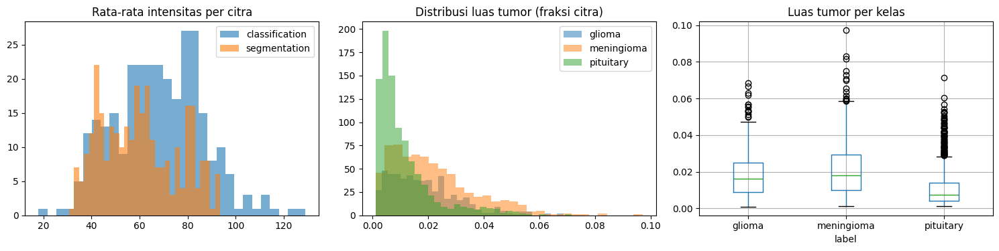

In [9]:
# 3d. Statistik ukuran & intensitas, luas mask, mask kosong, mismatch ukuran image-mask
def sample_stats(df, n=300):
    sub = df.sample(min(n, len(df)), random_state=SEED); sizes, means = Counter(), []
    for p in sub.image:
        im = read_gray(p); sizes[im.shape] += 1; means.append(im.mean())
    return sizes, np.array(means)
sz_cls, mu_cls = sample_stats(cls_tr); sz_seg, mu_seg = sample_stats(seg_df)
print("Ukuran citra klasifikasi (top 5):", sz_cls.most_common(5))
print("Ukuran citra segmentasi  (top 5):", sz_seg.most_common(5))

areas, mismatch = [], 0
for r in tqdm(seg_df.itertuples(), total=len(seg_df), desc="mask stats"):
    mk = read_gray(r.mask); areas.append(float((mk > 127).mean()))
    mismatch += Image.open(r.image).size != Image.open(r.mask).size
seg_df["area"] = areas
print(f"\nMask kosong: {(seg_df.area == 0).sum()} | image-mask beda ukuran: {mismatch}")
print(seg_df.groupby("label").area.describe()[["count", "mean", "50%", "min", "max"]].round(4))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(mu_cls, 30, alpha=.6, label="classification"); ax[0].hist(mu_seg, 30, alpha=.6, label="segmentation")
ax[0].set_title("Rata-rata intensitas per citra"); ax[0].legend()
for c in segc: ax[1].hist(seg_df[seg_df.label == c].area, 30, alpha=.5, label=c)
ax[1].set_title("Distribusi luas tumor (fraksi citra)"); ax[1].legend()
seg_df.boxplot(column="area", by="label", ax=ax[2]); ax[2].set_title("Luas tumor per kelas"); plt.suptitle("")
plt.tight_layout(); plt.show()

In [10]:
# 3e. Deteksi duplikat & kebocoran antar-split (aHash 16x16)
def ahash(path):
    im = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if im is None: return ""
    s = cv2.resize(im, (16, 16), interpolation=cv2.INTER_AREA)
    return (s > s.mean()).tobytes().hex()

for d in (seg_df, cls_tr, cls_va, cls_te):
    d["hash"] = [ahash(p) for p in tqdm(d.image, desc="hash", leave=False)]

H = lambda d: set(d.hash)
print("Duplikat internal seg_df        :", seg_df.hash.duplicated().sum())
print("Seg  ∩ Classification-Test      :", len(H(seg_df) & H(cls_te)))
print("Seg  ∩ Classification-Train/Val :", len(H(seg_df) & (H(cls_tr) | H(cls_va))))
print("Cls Train ∩ Test                :", len(H(cls_tr) & H(cls_te)))
print("Cls Train ∩ Val                 :", len(H(cls_tr) & H(cls_va)))

if FILTER_LEAK:
    n0 = (len(seg_df), len(cls_tr), len(cls_va))
    seg_df = seg_df.drop_duplicates("hash")
    seg_df = seg_df[~seg_df.hash.isin(H(cls_te))].reset_index(drop=True)      # seg model tak boleh lihat citra test
    cls_tr = cls_tr[~cls_tr.hash.isin(H(cls_te))].reset_index(drop=True)
    cls_va = cls_va[~cls_va.hash.isin(H(cls_te)) & ~cls_va.hash.isin(H(cls_tr))].reset_index(drop=True)
    seg_tr, seg_va, seg_te = split_seg(seg_df)
    print(f"\nFilter diterapkan. seg {n0[0]}->{len(seg_df)} | cls train {n0[1]}->{len(cls_tr)} | cls val {n0[2]}->{len(cls_va)}")

hash:   0%|          | 0/2192 [00:00<?, ?it/s]

hash:   0%|          | 0/4855 [00:00<?, ?it/s]

hash:   0%|          | 0/857 [00:00<?, ?it/s]

hash:   0%|          | 0/1311 [00:00<?, ?it/s]

Duplikat internal seg_df        : 33
Seg  ∩ Classification-Test      : 103
Seg  ∩ Classification-Train/Val : 544
Cls Train ∩ Test                : 277
Cls Train ∩ Val                 : 108

Filter diterapkan. seg 2192->2056 | cls train 4855->4437 | cls val 857->711


## Tahap 4 — Transforms & Data Augmentation

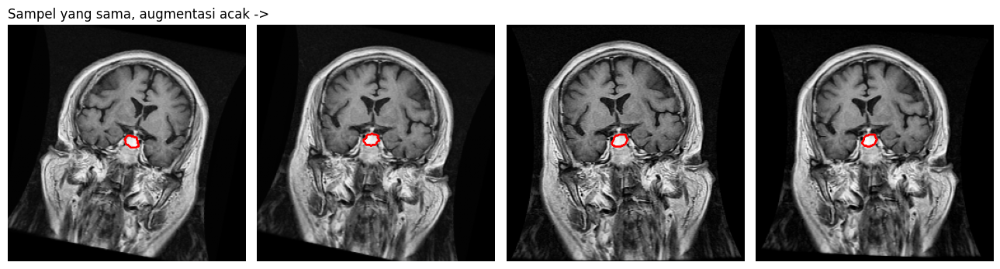

In [11]:
class SegDataset(Dataset):
    # Augmentasi dilakukan identik pada image & mask (mask: interpolasi nearest)
    def __init__(self, df, train=False, size=SEG_SIZE):
        self.df, self.train, self.size = df.reset_index(drop=True), train, size
    def __len__(self): return len(self.df)
    def _aug(self, img, msk):
        h, w = img.shape
        if random.random() < 0.5: img, msk = img[:, ::-1], msk[:, ::-1]
        if random.random() < 0.2: img, msk = img[::-1], msk[::-1]
        img, msk = np.ascontiguousarray(img), np.ascontiguousarray(msk)
        if random.random() < 0.5:
            M = cv2.getRotationMatrix2D((w/2, h/2), random.uniform(-15, 15), random.uniform(0.9, 1.1))
            img = cv2.warpAffine(img, M, (w, h), flags=cv2.INTER_LINEAR,  borderValue=0)
            msk = cv2.warpAffine(msk, M, (w, h), flags=cv2.INTER_NEAREST, borderValue=0)
        if random.random() < 0.5:
            img = np.clip(img.astype(np.float32) * random.uniform(0.85, 1.15) + random.uniform(-12, 12), 0, 255).astype(np.uint8)
        return img, msk
    def __getitem__(self, i):
        r = self.df.iloc[i]
        img = cv2.resize(read_gray(r.image), (self.size, self.size), interpolation=cv2.INTER_AREA)
        msk = (cv2.resize(read_gray(r["mask"]), (self.size, self.size), interpolation=cv2.INTER_NEAREST) > 127).astype(np.uint8)
        if self.train: img, msk = self._aug(img, msk)
        x = (torch.from_numpy(img.astype(np.float32) / 255.0)[None] - 0.5) / 0.5
        return x, torch.from_numpy(msk.astype(np.float32))[None]

# Augmentasi klasifikasi (dipakai di Tahap 10, diterapkan ke ROI)
train_tf = T.Compose([T.RandomHorizontalFlip(), T.RandomRotation(12),
                      T.RandomAffine(0, translate=(0.05, 0.05), scale=(0.93, 1.07)),
                      T.ColorJitter(brightness=0.25, contrast=0.25),
                      T.ToTensor(), T.Normalize(MEAN, STD), T.RandomErasing(p=0.15, scale=(0.02, 0.08))])

# Demo augmentasi segmentasi
ds_demo = SegDataset(seg_tr, True); k = random.randrange(len(ds_demo))
fig, ax = plt.subplots(1, 4, figsize=(13, 3.5))
for a in ax:
    x, y = ds_demo[k]; a.imshow(x[0] * .5 + .5, cmap="gray"); a.contour(y[0].numpy(), colors="red", linewidths=1); a.axis("off")
ax[0].set_title("Sampel yang sama, augmentasi acak ->", loc="left"); plt.tight_layout(); plt.show()

## Tahap 5 — Data Loaders (Stage 1)

In [20]:
def mk_loader(ds, bs, shuffle=False, sampler=None):
    return DataLoader(ds, batch_size=bs, shuffle=shuffle if sampler is None else False, sampler=sampler,
                      num_workers=NUM_WORKERS, pin_memory=DEVICE.type == "cuda", drop_last=(shuffle or sampler is not None))

seg_train_dl = mk_loader(SegDataset(seg_tr, True),  SEG_BS, shuffle=True)
seg_val_dl   = mk_loader(SegDataset(seg_va, False), SEG_BS)
seg_test_dl  = mk_loader(SegDataset(seg_te, False), SEG_BS)
print("batches:", len(seg_train_dl), len(seg_val_dl), len(seg_test_dl))

batches: 102 13 13


## Tahap 6 — Stage 1: Model Architecture (Attention U-Net)

In [13]:
# @@SHARED:arch
class ConvBlock(nn.Module):
    def __init__(self, i, o):
        super().__init__()
        self.net = nn.Sequential(nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(True),
                                 nn.Conv2d(o, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(True))
    def forward(self, x): return self.net(x)

class AttGate(nn.Module):
    def __init__(self, fg, fl, fi):
        super().__init__()
        self.wg  = nn.Sequential(nn.Conv2d(fg, fi, 1), nn.BatchNorm2d(fi))
        self.wx  = nn.Sequential(nn.Conv2d(fl, fi, 1), nn.BatchNorm2d(fi))
        self.psi = nn.Sequential(nn.Conv2d(fi, 1, 1), nn.BatchNorm2d(1), nn.Sigmoid())
    def forward(self, g, x): return x * self.psi(F.relu(self.wg(g) + self.wx(x)))

class AttentionUNet(nn.Module):
    def __init__(self, in_ch=1, out_ch=1, base=32):
        super().__init__()
        c = [base, base*2, base*4, base*8, base*16]
        self.enc  = nn.ModuleList([ConvBlock(in_ch, c[0]), ConvBlock(c[0], c[1]), ConvBlock(c[1], c[2]), ConvBlock(c[2], c[3])])
        self.pool = nn.MaxPool2d(2)
        self.bott = ConvBlock(c[3], c[4])
        self.up   = nn.ModuleList([nn.ConvTranspose2d(c[i+1], c[i], 2, stride=2) for i in range(3, -1, -1)])
        self.att  = nn.ModuleList([AttGate(c[i], c[i], c[i] // 2) for i in range(3, -1, -1)])
        self.dec  = nn.ModuleList([ConvBlock(c[i] * 2, c[i]) for i in range(3, -1, -1)])
        self.head = nn.Conv2d(c[0], out_ch, 1)
    def forward(self, x):
        skips = []
        for e in self.enc:
            x = e(x); skips.append(x); x = self.pool(x)
        x = self.bott(x)
        for up, att, dec, s in zip(self.up, self.att, self.dec, reversed(skips)):
            x = up(x); s = att(x, s); x = dec(torch.cat([x, s], 1))
        return self.head(x)       # logits

In [14]:
_m = AttentionUNet().to(DEVICE)
print("Output:", tuple(_m(torch.zeros(2, 1, SEG_SIZE, SEG_SIZE, device=DEVICE)).shape),
      "| params:", f"{sum(p.numel() for p in _m.parameters())/1e6:.2f}M"); del _m

Output: (2, 1, 256, 256) | params: 7.85M


## Tahap 7 — Stage 1: Loss & Training Setup

In [15]:
def dice_loss(logits, y, eps=1e-6):
    p = torch.sigmoid(logits).flatten(1); y = y.flatten(1)
    return (1 - (2 * (p * y).sum(1) + eps) / (p.sum(1) + y.sum(1) + eps)).mean()

class BCEDiceLoss(nn.Module):
    def __init__(self, w_bce=0.5, w_dice=0.5):
        super().__init__(); self.bce = nn.BCEWithLogitsLoss(); self.wb, self.wd = w_bce, w_dice
    def forward(self, logits, y): return self.wb * self.bce(logits, y) + self.wd * dice_loss(logits, y)

@torch.no_grad()
def seg_metrics(logits, y, thr=SEG_THR, eps=1e-6):
    p = (torch.sigmoid(logits) > thr).float().flatten(1); y = y.flatten(1)
    inter = (p * y).sum(1)
    return ((2*inter + eps) / (p.sum(1) + y.sum(1) + eps)).mean().item(), ((inter + eps) / (p.sum(1) + y.sum(1) - inter + eps)).mean().item()

class EarlyStopping:
    # Simpan checkpoint terbaik otomatis; stop jika tidak membaik selama `patience` epoch.
    def __init__(self, patience, ckpt, mode="max"):
        self.patience, self.ckpt, self.mode, self.best, self.bad = patience, ckpt, mode, None, 0
    def reset_bad(self): self.bad = 0
    def step(self, value, model):
        better = self.best is None or (value > self.best if self.mode == "max" else value < self.best)
        if better: self.best, self.bad = value, 0; torch.save(model.state_dict(), self.ckpt)
        else: self.bad += 1
        return self.bad >= self.patience

def seg_setup(model):
    opt   = torch.optim.AdamW(model.parameters(), lr=SEG_LR, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.5, patience=3)
    return BCEDiceLoss(), opt, sched, torch.amp.GradScaler(enabled=USE_AMP)

## Tahap 8 — Stage 1: Training Loop & Curves

In [21]:
def run_seg_epoch(model, dl, crit, opt=None, scaler=None):
    train = opt is not None; model.train(train); tot = ds_ = is_ = n = 0
    for x, y in tqdm(dl, leave=False):
        x, y = x.to(DEVICE), y.to(DEVICE)
        with torch.set_grad_enabled(train):
            with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
                logits = model(x); loss = crit(logits.float(), y)
        if train:
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        d, i = seg_metrics(logits.float(), y); b = x.size(0)
        tot += loss.item()*b; ds_ += d*b; is_ += i*b; n += b
    return tot/n, ds_/n, is_/n

seg_model = AttentionUNet().to(DEVICE)
if TRAIN_SEG:
    crit, opt, sched, scaler = seg_setup(seg_model)
    es = EarlyStopping(PATIENCE_SEG, SEG_CKPT, "max"); seg_hist = []
    for ep in range(1, SEG_EPOCHS + 1):
        t0 = time.time()
        trl, trd, tri = run_seg_epoch(seg_model, seg_train_dl, crit, opt, scaler)
        vl, vd, vi = run_seg_epoch(seg_model, seg_val_dl, crit)
        sched.step(vd); seg_hist.append(dict(ep=ep, tr_loss=trl, va_loss=vl, tr_dice=trd, va_dice=vd, tr_iou=tri, va_iou=vi))
        print(f"[{ep:02d}] loss {trl:.4f}/{vl:.4f} | dice {trd:.4f}/{vd:.4f} | iou {tri:.4f}/{vi:.4f} | {time.time()-t0:.0f}s")
        if es.step(vd, seg_model): print("Early stopping."); break
    seg_hist = pd.DataFrame(seg_hist)
seg_model.load_state_dict(torch.load(SEG_CKPT, map_location=DEVICE)); seg_model.eval()

_, seg_test_dice, seg_test_iou = run_seg_epoch(seg_model, seg_test_dl, BCEDiceLoss())
print(f"\nSEG TEST -> Dice {seg_test_dice:.4f} | IoU {seg_test_iou:.4f}")

  0%|          | 0/102 [00:00<?, ?it/s]

  0%|          | 0/13 [00:00<?, ?it/s]

[01] loss 0.6575/0.6128 | dice 0.2166/0.2976 | iou 0.1595/0.2102 | 44s


  0%|          | 0/102 [00:00<?, ?it/s]

  0%|          | 0/13 [00:00<?, ?it/s]

[02] loss 0.5838/0.5671 | dice 0.3907/0.3450 | iou 0.2883/0.2720 | 44s


... (172 outputs left out)

  0%|          | 0/13 [00:00<?, ?it/s]

[60] loss 0.0898/0.1255 | dice 0.8465/0.7811 | iou 0.7586/0.6928 | 43s


  0%|          | 0/13 [00:00<?, ?it/s]


SEG TEST -> Dice 0.7756 | IoU 0.6880


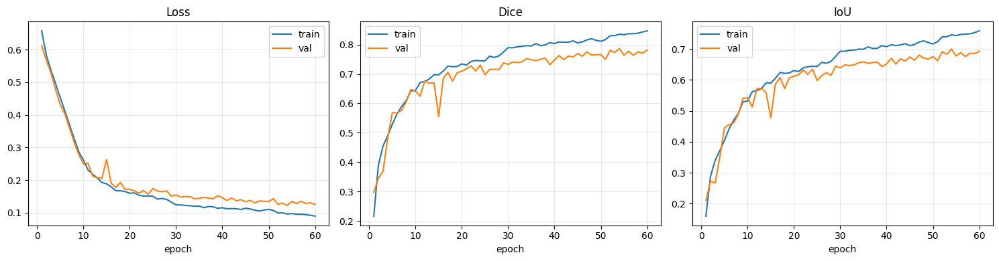

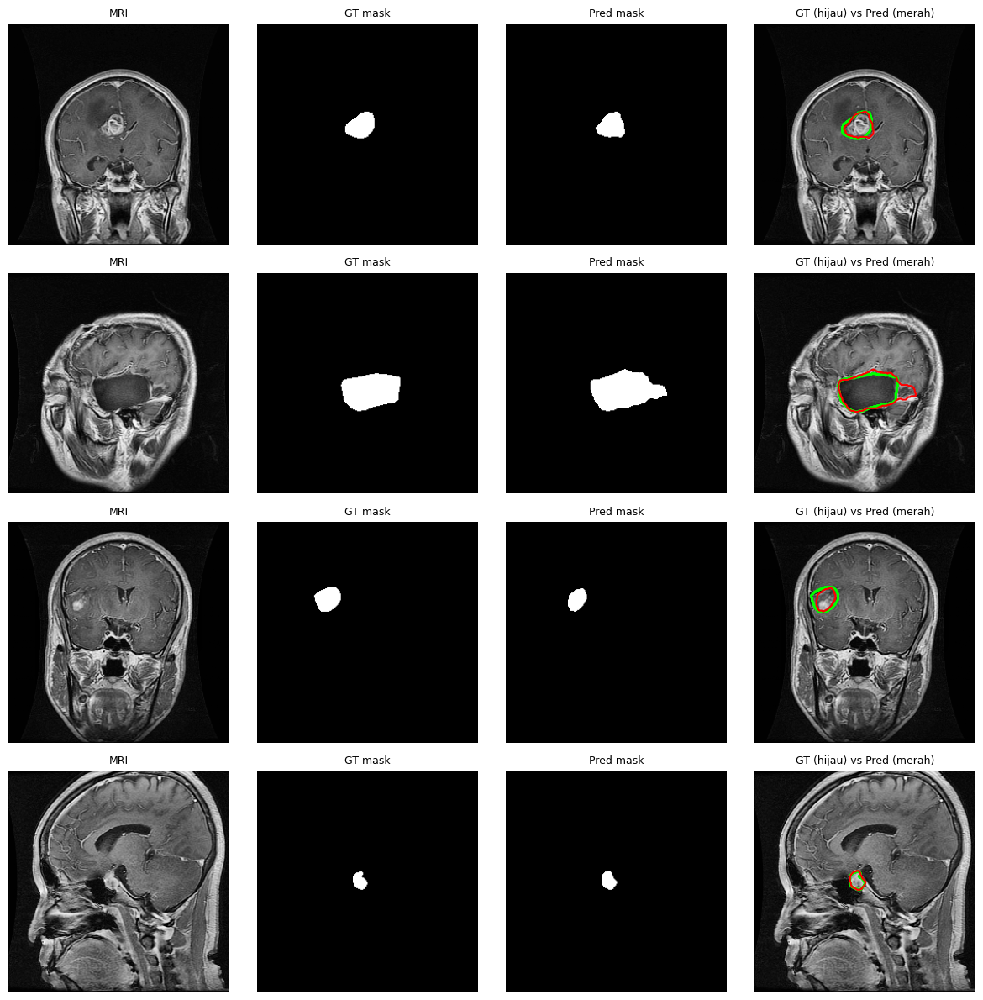

In [22]:
if TRAIN_SEG:
    fig, ax = plt.subplots(1, 3, figsize=(15, 4))
    for a, (k, t) in zip(ax, [("loss", "Loss"), ("dice", "Dice"), ("iou", "IoU")]):
        a.plot(seg_hist.ep, seg_hist[f"tr_{k}"], label="train"); a.plot(seg_hist.ep, seg_hist[f"va_{k}"], label="val")
        a.set_title(t); a.set_xlabel("epoch"); a.legend(); a.grid(alpha=.3)
    plt.tight_layout(); plt.show()

ds = SegDataset(seg_te, False)
fig, ax = plt.subplots(4, 4, figsize=(12, 12))
for r, i in enumerate(random.sample(range(len(ds)), 4)):
    x, y = ds[i]
    with torch.no_grad(): p = torch.sigmoid(seg_model(x[None].to(DEVICE)))[0, 0].cpu().numpy()
    ax[r, 0].imshow(x[0]*.5 + .5, cmap="gray"); ax[r, 1].imshow(y[0], cmap="gray"); ax[r, 2].imshow(p > SEG_THR, cmap="gray")
    ax[r, 3].imshow(x[0]*.5 + .5, cmap="gray"); ax[r, 3].contour(y[0].numpy(), colors="lime"); ax[r, 3].contour(p > SEG_THR, colors="red")
    for c, t in enumerate(["MRI", "GT mask", "Pred mask", "GT (hijau) vs Pred (merah)"]): ax[r, c].set_title(t, fontsize=9); ax[r, c].axis("off")
plt.tight_layout(); plt.show()

## Tahap 9 — The Bridge: ROI Masking & Cropping
Mask diprediksi Stage 1 (di-**freeze**), komponen kecil dibuang, citra x mask (background di-nol-kan), crop bounding box + margin, pad jadi persegi, resize. Jika tidak ada tumor terdeteksi (mis. kelas `notumor`) -> **fallback** ke citra penuh.

In [23]:
# @@SHARED:roi
EVAL_TF = T.Compose([T.ToTensor(), T.Normalize(MEAN, STD)])

@torch.no_grad()
def predict_prob_batch(seg_model, imgs):
    # imgs: list of uint8 gray (ukuran bebas) -> list of prob map (ukuran asli)
    seg_model.eval()
    xs = [cv2.resize(im, (SEG_SIZE, SEG_SIZE), interpolation=cv2.INTER_AREA) for im in imgs]
    x = torch.from_numpy((np.stack(xs).astype(np.float32) / 255.0 - 0.5) / 0.5)[:, None].to(DEVICE)
    with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
        p = torch.sigmoid(seg_model(x).float()).cpu().numpy()[:, 0]
    return [cv2.resize(pi, (im.shape[1], im.shape[0]), interpolation=cv2.INTER_LINEAR) for pi, im in zip(p, imgs)]

def extract_roi(img, prob, thr=SEG_THR, margin=ROI_MARGIN, min_area=MIN_AREA, out_size=CLS_SIZE):
    # Return: roi (out_size x out_size uint8), clean_mask (HxW uint8), bbox (x0,y0,x1,y1), used_fallback (bool)
    H, W = img.shape
    m = (prob > thr).astype(np.uint8)
    n, lab, stats, _ = cv2.connectedComponentsWithStats(m, connectivity=8)
    keep = np.zeros_like(m)
    for k in range(1, n):
        if stats[k, cv2.CC_STAT_AREA] >= min_area * H * W: keep[lab == k] = 1
    if keep.sum() == 0:
        crop, bbox, fb = img, (0, 0, W, H), True
    else:
        masked = img * keep
        ys, xs = np.where(keep > 0)
        x0, x1, y0, y1 = xs.min(), xs.max() + 1, ys.min(), ys.max() + 1
        mx, my = int((x1 - x0) * margin), int((y1 - y0) * margin)
        x0, y0, x1, y1 = max(0, x0 - mx), max(0, y0 - my), min(W, x1 + mx), min(H, y1 + my)
        crop, bbox, fb = masked[y0:y1, x0:x1], (int(x0), int(y0), int(x1), int(y1)), False
    h, w = crop.shape; s = max(h, w)
    pad = np.zeros((s, s), np.uint8)
    pad[(s-h)//2:(s-h)//2 + h, (s-w)//2:(s-w)//2 + w] = crop          # pad persegi, aspect ratio terjaga
    return cv2.resize(pad, (out_size, out_size), interpolation=cv2.INTER_AREA), keep, bbox, fb

def cls_preprocess(roi):
    return EVAL_TF(Image.fromarray(roi).convert("RGB"))[None].to(DEVICE)

In [24]:
for p in seg_model.parameters(): p.requires_grad = False       # freeze Stage 1
seg_model.eval()

def build_roi_cache(df, split, bs=32):
    out, paths, fbs = ROI_CACHE / split, [], []
    for c in CLASSES: (out / c).mkdir(parents=True, exist_ok=True)
    for s in tqdm(range(0, len(df), bs), desc=f"ROI {split}"):
        chunk = df.iloc[s:s + bs]; imgs = [read_gray(p) for p in chunk.image]
        for j, (img, pr, lbl) in enumerate(zip(imgs, predict_prob_batch(seg_model, imgs), chunk.label)):
            roi, _, _, fb = extract_roi(img, pr)
            fp = out / lbl / f"{s + j:05d}.png"; cv2.imwrite(str(fp), roi); paths.append(str(fp)); fbs.append(fb)
    df = df.copy().reset_index(drop=True); df["roi"] = paths; df["fallback"] = fbs
    return df

cls_tr = build_roi_cache(cls_tr, "train")
cls_va = build_roi_cache(cls_va, "val")
cls_te = build_roi_cache(cls_te, "test")
print("Fallback rate per kelas (train) — kelas tumor idealnya rendah, notumor tinggi:")
print(cls_tr.groupby("label").fallback.mean().round(3))

ROI train:   0%|          | 0/139 [00:00<?, ?it/s]

ROI val:   0%|          | 0/23 [00:00<?, ?it/s]

ROI test:   0%|          | 0/41 [00:00<?, ?it/s]

Fallback rate per kelas (train) — kelas tumor idealnya rendah, notumor tinggi:
label
glioma        0.039
meningioma    0.032
notumor       0.744
pituitary     0.041
Name: fallback, dtype: float64


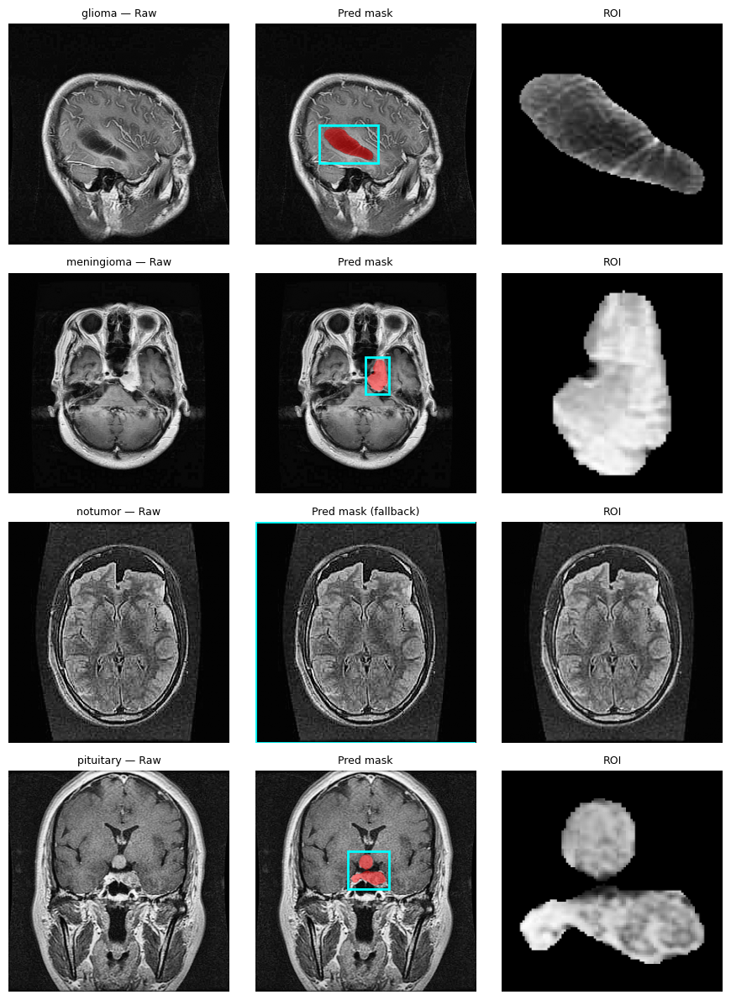

In [25]:
# Visualisasi bridge: Raw -> Mask prediksi -> ROI (1 contoh per kelas, test set)
fig, ax = plt.subplots(len(CLASSES), 3, figsize=(9, 3 * len(CLASSES)))
for r, c in enumerate(CLASSES):
    row = cls_te[cls_te.label == c].sample(1, random_state=SEED).iloc[0]
    img = read_gray(row.image); pr = predict_prob_batch(seg_model, [img])[0]; roi, mk, bb, fb = extract_roi(img, pr)
    ax[r, 0].imshow(img, cmap="gray"); ax[r, 1].imshow(img, cmap="gray"); ax[r, 1].imshow(np.ma.masked_where(mk == 0, mk), cmap="autumn", alpha=.5)
    ax[r, 1].add_patch(plt.Rectangle((bb[0], bb[1]), bb[2]-bb[0], bb[3]-bb[1], fill=False, ec="cyan", lw=2)); ax[r, 2].imshow(roi, cmap="gray")
    ax[r, 0].set_title(f"{c} — Raw", fontsize=9); ax[r, 1].set_title("Pred mask" + (" (fallback)" if fb else ""), fontsize=9); ax[r, 2].set_title("ROI", fontsize=9)
    for a in ax[r]: a.axis("off")
plt.tight_layout(); plt.show()

## Tahap 10 — Stage 2: Data Loaders (Balancer)

Distribusi label 1 epoch (setelah sampler): {'glioma': 1077, 'meningioma': 1144, 'notumor': 1113, 'pituitary': 1082}
class weights (focal): {'glioma': np.float64(0.994), 'meningioma': np.float64(1.03), 'notumor': np.float64(1.028), 'pituitary': np.float64(0.948)}


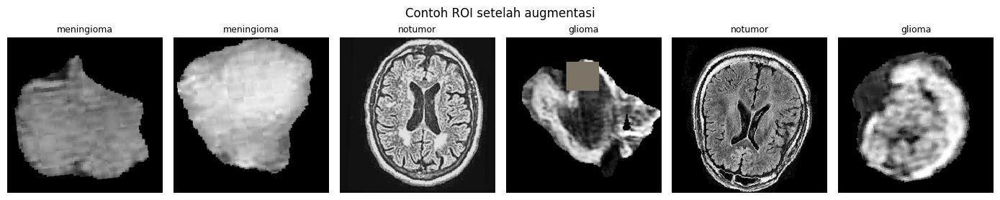

In [26]:
L2I = {c: i for i, c in enumerate(CLASSES)}
class ROIDataset(Dataset):
    def __init__(self, df, tf): self.df, self.tf = df.reset_index(drop=True), tf
    def __len__(self): return len(self.df)
    def __getitem__(self, i):
        r = self.df.iloc[i]; return self.tf(Image.open(r.roi).convert("RGB")), L2I[r.label]

counts = cls_tr.label.value_counts().reindex(CLASSES).values.astype(np.float64)
sample_w = cls_tr.label.map(dict(zip(CLASSES, 1.0 / counts))).values
sampler = WeightedRandomSampler(torch.DoubleTensor(sample_w), num_samples=len(cls_tr), replacement=True)

cls_train_dl = mk_loader(ROIDataset(cls_tr, train_tf), CLS_BS, sampler=sampler)    # kelas diseimbangkan saat sampling
cls_val_dl   = mk_loader(ROIDataset(cls_va, EVAL_TF),  CLS_BS)
cls_test_dl  = mk_loader(ROIDataset(cls_te, EVAL_TF),  CLS_BS)

# cek keseimbangan batch hasil sampler
seen = Counter()
for _, y in cls_train_dl: seen.update(y.tolist())
print("Distribusi label 1 epoch (setelah sampler):", {CLASSES[k]: seen[k] for k in sorted(seen)})

# alpha lunak (akar) untuk focal loss agar tidak 'double-compensate' dengan sampler
alpha = np.sqrt(counts.sum() / (len(CLASSES) * counts)); alpha = alpha / alpha.mean()
print("class weights (focal):", dict(zip(CLASSES, alpha.round(3))))

xb, yb = next(iter(cls_train_dl)); fig, ax = plt.subplots(1, 6, figsize=(14, 2.8))
for i, a in enumerate(ax):
    a.imshow((xb[i] * torch.tensor(STD)[:, None, None] + torch.tensor(MEAN)[:, None, None]).permute(1, 2, 0).clamp(0, 1)); a.set_title(CLASSES[yb[i]], fontsize=9); a.axis("off")
plt.suptitle("Contoh ROI setelah augmentasi"); plt.tight_layout(); plt.show()

## Tahap 11 — Stage 2: Model Architecture (EfficientNet-B4 & ResNet-50)

In [27]:
# @@SHARED:cls
class EffNetB4Classifier(nn.Module):
    # EfficientNet-B4 -> GAP -> Dropout -> Dense(4)
    def __init__(self, n_cls=4, pretrained=True, drop=0.4):
        super().__init__()
        try:
            m = torchvision.models.efficientnet_b4(weights=torchvision.models.EfficientNet_B4_Weights.DEFAULT if pretrained else None)
        except Exception as e:
            print("Pretrained EffNet-B4 gagal diunduh, random init:", e); m = torchvision.models.efficientnet_b4(weights=None)
        self.backbone = m.features
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.head = nn.Sequential(nn.Dropout(drop), nn.Linear(1792, n_cls))
    def forward(self, x): return self.head(self.pool(self.backbone(x)).flatten(1))
    def partial_layers(self): return [self.backbone[6], self.backbone[7], self.backbone[8]]   # 3 stage terakhir
    def cam_layer(self): return self.backbone[-1]

class ResNet50Classifier(nn.Module):
    # ResNet-50 -> GAP -> Dropout -> Dense(4)
    def __init__(self, n_cls=4, pretrained=True, drop=0.4):
        super().__init__()
        try:
            m = torchvision.models.resnet50(weights=torchvision.models.ResNet50_Weights.DEFAULT if pretrained else None)
        except Exception as e:
            print("Pretrained ResNet-50 gagal diunduh, random init:", e); m = torchvision.models.resnet50(weights=None)
        self.backbone = nn.Sequential(m.conv1, m.bn1, m.relu, m.maxpool, m.layer1, m.layer2, m.layer3, m.layer4)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.head = nn.Sequential(nn.Dropout(drop), nn.Linear(2048, n_cls))
    def forward(self, x): return self.head(self.pool(self.backbone(x)).flatten(1))
    def partial_layers(self): return [self.backbone[-1]]                                      # layer4
    def cam_layer(self): return self.backbone[-1]

class EnsembleClassifier(nn.Module):
    # Output = probabilitas rata-rata berbobot (sudah softmax)
    def __init__(self, models, weights):
        super().__init__()
        self.models = nn.ModuleList(models)
        self.register_buffer("w", torch.tensor(weights, dtype=torch.float32))
    def forward(self, x):
        return sum(self.w[i] * F.softmax(m(x).float(), 1) for i, m in enumerate(self.models))

In [28]:
MODEL_CTORS = {"effnet_b4": EffNetB4Classifier, "resnet50": ResNet50Classifier}
for n, ctor in MODEL_CTORS.items():
    _m = ctor(pretrained=False).to(DEVICE).eval()
    print(f"{n:>10}: out {tuple(_m(torch.zeros(2, 3, CLS_SIZE, CLS_SIZE, device=DEVICE)).shape)} | params {sum(p.numel() for p in _m.parameters())/1e6:.1f}M")
    del _m

 effnet_b4: out (2, 4) | params 17.6M
  resnet50: out (2, 4) | params 23.5M


## Tahap 12 — Loss Function & Training Setup (Focal Loss, AdamW, ReduceLROnPlateau)

In [29]:
class FocalLoss(nn.Module):
    # Categorical focal loss + class weights (+ label smoothing kecil)
    def __init__(self, alpha=None, gamma=2.0, smoothing=0.05):
        super().__init__(); self.gamma, self.smoothing = gamma, smoothing
        self.register_buffer("alpha", None if alpha is None else torch.tensor(alpha, dtype=torch.float32))
    def forward(self, logits, y):
        ce = F.cross_entropy(logits, y, reduction="none", label_smoothing=self.smoothing)
        loss = (1 - torch.exp(-ce)) ** self.gamma * ce
        if self.alpha is not None: loss = loss * self.alpha[y]
        return loss.mean()

focal = FocalLoss(alpha).to(DEVICE)

PHASES = [  # 3 fase fine-tuning
    dict(name="1-head",    epochs=3,  mode="head",    lr_head=1e-3, lr_bb=0.0),    # backbone beku total
    dict(name="2-partial", epochs=7,  mode="partial", lr_head=5e-4, lr_bb=1e-4),   # unfreeze sebagian
    dict(name="3-full",    epochs=30, mode="full",    lr_head=1e-4, lr_bb=2e-5),   # unfreeze penuh
]
def set_trainable(model, mode):
    for p in model.parameters(): p.requires_grad = False
    for p in model.head.parameters(): p.requires_grad = True
    if mode == "partial":
        for m in model.partial_layers():
            for p in m.parameters(): p.requires_grad = True
    elif mode == "full":
        for p in model.parameters(): p.requires_grad = True

def make_optimizer(model, lr_head, lr_bb):
    groups = [{"params": list(model.head.parameters()), "lr": lr_head}]
    bb = [p for p in model.backbone.parameters() if p.requires_grad]
    if bb: groups.append({"params": bb, "lr": lr_bb})            # LR backbone < LR head
    opt = torch.optim.AdamW(groups, weight_decay=1e-2)
    return opt, torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.5, patience=2)

## Tahap 13 — Training Loop (3 fase: freeze total -> unfreeze sebagian -> unfreeze penuh)

In [30]:
@torch.no_grad()
def get_logits(model, dl):
    model.eval(); L, Y = [], []
    for x, y in dl:
        with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP): lo = model(x.to(DEVICE))
        L.append(lo.float().cpu().numpy()); Y.append(y.numpy())
    return np.concatenate(L), np.concatenate(Y)

def softmax_np(z): e = np.exp(z - z.max(1, keepdims=True)); return e / e.sum(1, keepdims=True)

def run_cls_epoch(model, dl, opt, scaler, freeze_bn):
    model.train()
    if freeze_bn: model.backbone.eval()          # fase 1: statistik BN backbone tidak ikut berubah
    tot = n = c = 0
    for x, y in tqdm(dl, leave=False):
        x, y = x.to(DEVICE), y.to(DEVICE)
        with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
            lo = model(x); loss = focal(lo.float(), y)
        opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        tot += loss.item() * x.size(0); n += x.size(0); c += (lo.argmax(1) == y).sum().item()
    return tot / n, c / n

def train_classifier(name):
    model = MODEL_CTORS[name]().to(DEVICE); ckpt = CLS_CKPT[name]
    es = EarlyStopping(PATIENCE_CLS, ckpt, "max"); scaler = torch.amp.GradScaler(enabled=USE_AMP); hist = []
    for ph in PHASES:
        if es.best is not None: model.load_state_dict(torch.load(ckpt, map_location=DEVICE))   # lanjut dari checkpoint terbaik
        set_trainable(model, ph["mode"]); opt, sched = make_optimizer(model, ph["lr_head"], ph["lr_bb"]); es.reset_bad()
        ntr = sum(p.numel() for p in model.parameters() if p.requires_grad)
        print(f"\n=== {name} | fase {ph['name']} | trainable {ntr/1e6:.2f}M ===")
        for _ in range(ph["epochs"]):
            t0 = time.time()
            trl, tra = run_cls_epoch(model, cls_train_dl, opt, scaler, freeze_bn=(ph["mode"] == "head"))
            lg, yv = get_logits(model, cls_val_dl); pv = lg.argmax(1)
            vl = focal(torch.from_numpy(lg).to(DEVICE), torch.from_numpy(yv).to(DEVICE)).item()
            va, vf = float((pv == yv).mean()), f1_score(yv, pv, average="macro")
            sched.step(vf)
            hist.append(dict(model=name, phase=ph["name"], ep=len(hist) + 1, tr_loss=trl, tr_acc=tra, va_loss=vl, va_acc=va, va_f1=vf))
            print(f"[{len(hist):02d}] loss {trl:.4f}/{vl:.4f} | acc {tra:.4f}/{va:.4f} | val F1 {vf:.4f} | {time.time()-t0:.0f}s")
            if es.step(vf, model): print("Early stopping (fase ini)."); break
    model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
    for p in model.parameters(): p.requires_grad = True
    return model.eval(), pd.DataFrame(hist)

models, hists = {}, {}
for name in MODEL_CTORS:
    if TRAIN_CLS:
        models[name], hists[name] = train_classifier(name)
    else:
        models[name] = MODEL_CTORS[name](pretrained=False).to(DEVICE); models[name].load_state_dict(torch.load(CLS_CKPT[name], map_location=DEVICE)); models[name].eval()

Downloading: "https://download.pytorch.org/models/efficientnet_b4_rwightman-23ab8bcd.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b4_rwightman-23ab8bcd.pth


100%|██████████| 74.5M/74.5M [00:00<00:00, 188MB/s]



=== effnet_b4 | fase 1-head | trainable 0.01M ===


  0%|          | 0/184 [00:00<?, ?it/s]

[01] loss 0.4492/0.3571 | acc 0.6540/0.7187 | val F1 0.7305 | 60s


  0%|          | 0/184 [00:00<?, ?it/s]

... (81 outputs left out)

  0%|          | 0/184 [00:00<?, ?it/s]

[23] loss 0.0518/0.1029 | acc 0.9624/0.9367 | val F1 0.9381 | 64s


  0%|          | 0/184 [00:00<?, ?it/s]

[24] loss 0.0416/0.1049 | acc 0.9708/0.9367 | val F1 0.9379 | 64s
Early stopping (fase ini).


## Tahap 14 — Training Curves

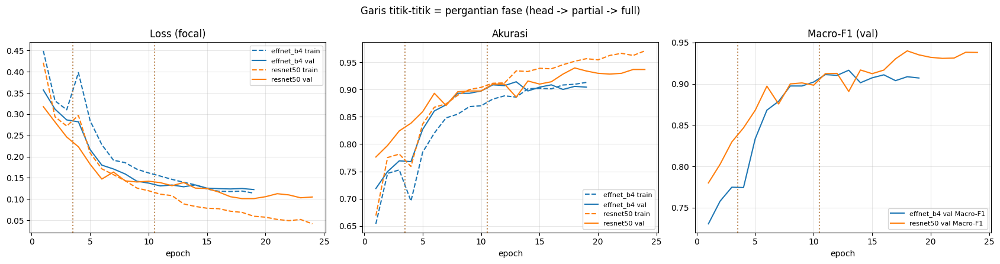

In [31]:
if hists:
    colors = {"effnet_b4": "tab:blue", "resnet50": "tab:orange"}
    fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
    for n, h in hists.items():
        ax[0].plot(h.ep, h.tr_loss, "--", c=colors[n], label=f"{n} train"); ax[0].plot(h.ep, h.va_loss, c=colors[n], label=f"{n} val")
        ax[1].plot(h.ep, h.tr_acc,  "--", c=colors[n], label=f"{n} train"); ax[1].plot(h.ep, h.va_acc,  c=colors[n], label=f"{n} val")
        ax[2].plot(h.ep, h.va_f1, c=colors[n], label=f"{n} val Macro-F1")
        for ph in h.phase.unique()[1:]:
            for a in ax: a.axvline(h[h.phase == ph].ep.min() - .5, c=colors[n], ls=":", alpha=.6)
    for a, t in zip(ax, ["Loss (focal)", "Akurasi", "Macro-F1 (val)"]): a.set_title(t); a.set_xlabel("epoch"); a.grid(alpha=.3); a.legend(fontsize=8)
    plt.suptitle("Garis titik-titik = pergantian fase (head -> partial -> full)"); plt.tight_layout(); plt.show()

## Tahap 15 — Evaluasi Individual & Ensemble (bobot dicari di validation, diterapkan ke test)

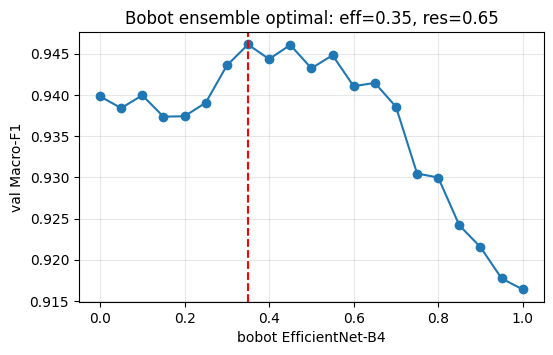

              acc  macro_f1
model                      
effnet_b4  0.8635    0.8560
resnet50   0.8825    0.8759
ensemble   0.8863    0.8805

=== Classification report (ENSEMBLE, test) ===
              precision    recall  f1-score   support

      glioma     0.9097    0.9400    0.9246       300
  meningioma     0.9083    0.6797    0.7776       306
     notumor     0.8628    0.9630    0.9102       405
   pituitary     0.8812    0.9400    0.9097       300

    accuracy                         0.8863      1311
   macro avg     0.8905    0.8807    0.8805      1311
weighted avg     0.8884    0.8863    0.8824      1311



In [32]:
val_p, test_p = {}, {}
for n, m in models.items():
    lg, yv = get_logits(m, cls_val_dl);  val_p[n]  = softmax_np(lg)
    lg, yt = get_logits(m, cls_test_dl); test_p[n] = softmax_np(lg)

ws = np.linspace(0, 1, 21)
f1s = np.array([f1_score(yv, (w * val_p["effnet_b4"] + (1 - w) * val_p["resnet50"]).argmax(1), average="macro") for w in ws])
cand = ws[f1s >= f1s.max() - 1e-9]; W_EFF = float(cand[np.argmin(np.abs(cand - 0.5))])      # seri -> pilih yang paling dekat 0.5
W_RES = 1.0 - W_EFF
plt.figure(figsize=(6, 3.5)); plt.plot(ws, f1s, marker="o"); plt.axvline(W_EFF, c="r", ls="--")
plt.xlabel("bobot EfficientNet-B4"); plt.ylabel("val Macro-F1"); plt.title(f"Bobot ensemble optimal: eff={W_EFF:.2f}, res={W_RES:.2f}"); plt.grid(alpha=.3); plt.show()

test_p["ensemble"] = W_EFF * test_p["effnet_b4"] + W_RES * test_p["resnet50"]
ensemble = EnsembleClassifier([models["effnet_b4"], models["resnet50"]], [W_EFF, W_RES]).to(DEVICE).eval()

rows = []
for n, p in test_p.items():
    pr = p.argmax(1); rows.append(dict(model=n, acc=(pr == yt).mean(), macro_f1=f1_score(yt, pr, average="macro")))
summary = pd.DataFrame(rows).set_index("model").round(4); print(summary)
print("\n=== Classification report (ENSEMBLE, test) ===")
print(classification_report(yt, test_p["ensemble"].argmax(1), target_names=CLASSES, digits=4))

## Tahap 16 — Confusion Matrix & ROC

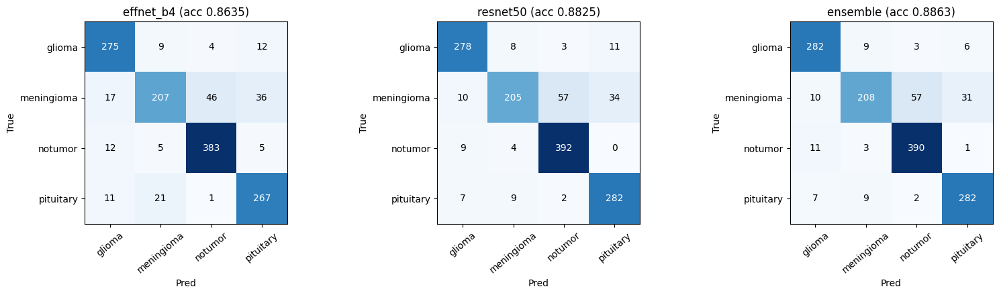

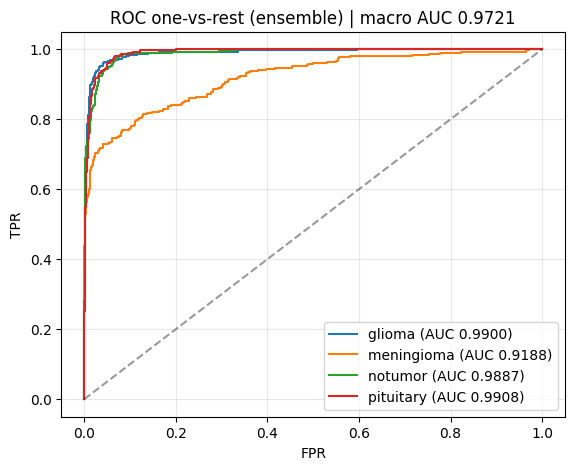

In [33]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, (n, p) in zip(ax, test_p.items()):
    cm = confusion_matrix(yt, p.argmax(1)); a.imshow(cm, cmap="Blues")
    a.set_xticks(range(4)); a.set_xticklabels(CLASSES, rotation=40); a.set_yticks(range(4)); a.set_yticklabels(CLASSES)
    for i in range(4):
        for j in range(4): a.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
    a.set_title(f"{n} (acc {(p.argmax(1) == yt).mean():.4f})"); a.set_xlabel("Pred"); a.set_ylabel("True")
plt.tight_layout(); plt.show()

Yb = label_binarize(yt, classes=range(4)); plt.figure(figsize=(6.5, 5)); aucs = []
for k, c in enumerate(CLASSES):
    fpr, tpr, _ = roc_curve(Yb[:, k], test_p["ensemble"][:, k]); aucs.append(auc(fpr, tpr)); plt.plot(fpr, tpr, label=f"{c} (AUC {aucs[-1]:.4f})")
plt.plot([0, 1], [0, 1], "k--", alpha=.4); plt.xlabel("FPR"); plt.ylabel("TPR"); plt.title(f"ROC one-vs-rest (ensemble) | macro AUC {np.mean(aucs):.4f}")
plt.legend(loc="lower right"); plt.grid(alpha=.3); plt.show()

## Tahap 17 — Prediction Visualization & Error Analysis

Akurasi per kelas:
label
glioma        0.9400
meningioma    0.6797
notumor       0.9630
pituitary     0.9400
Name: correct, dtype: float64

Confidence rata-rata  benar: 0.848 | salah: 0.625

Akurasi berdasarkan status ROI (fallback = mask kosong):
                       mean  count
label      fallback               
glioma     False     0.9401    284
           True      0.9375     16
meningioma False     0.7409    274
           True      0.1562     32
notumor    False     0.8352     91
           True      1.0000    314
pituitary  False     0.9386    293
           True      1.0000      7

Pasangan salah paling sering (True -> Pred):
label       pred      
meningioma  notumor       57
            pituitary     31
notumor     glioma        11
meningioma  glioma        10
glioma      meningioma     9
pituitary   meningioma     9
            glioma         7
glioma      pituitary      6
dtype: int64


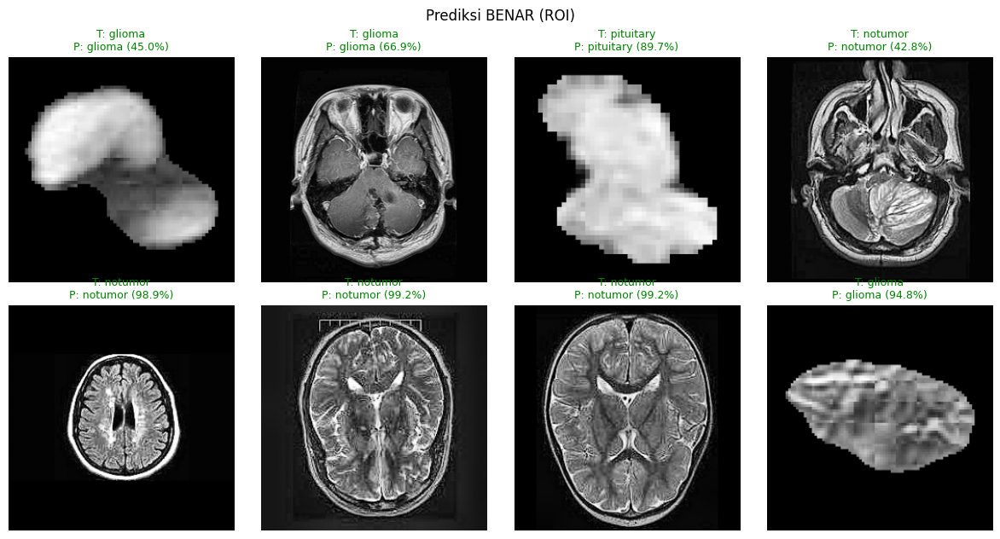

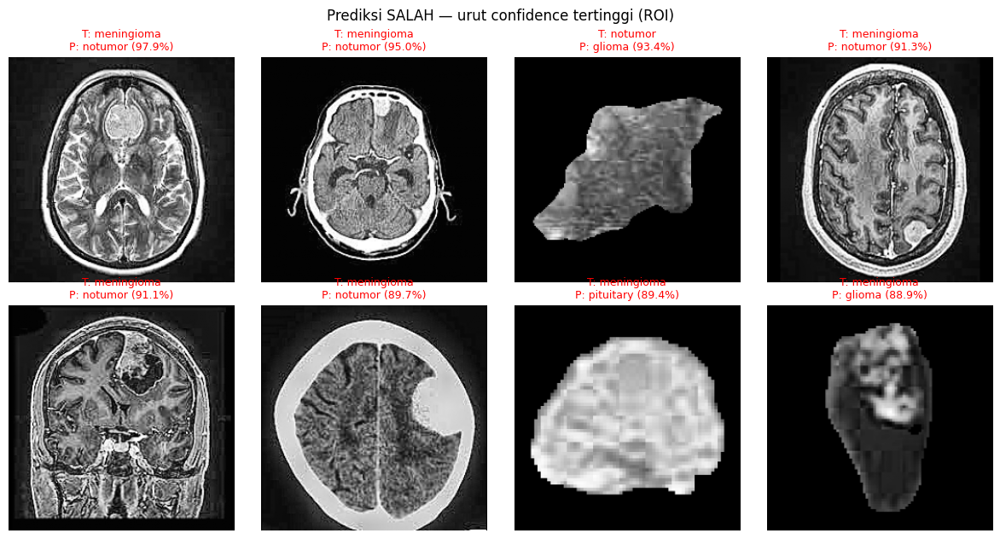

In [34]:
pe = test_p["ensemble"]
cls_te["pred"] = [CLASSES[i] for i in pe.argmax(1)]; cls_te["conf"] = pe.max(1); cls_te["correct"] = cls_te.pred == cls_te.label

print("Akurasi per kelas:"); print(cls_te.groupby("label").correct.mean().round(4))
print("\nConfidence rata-rata  benar: %.3f | salah: %.3f" % (cls_te[cls_te.correct].conf.mean(), cls_te[~cls_te.correct].conf.mean() if (~cls_te.correct).any() else float("nan")))
print("\nAkurasi berdasarkan status ROI (fallback = mask kosong):"); print(cls_te.groupby(["label", "fallback"]).correct.agg(["mean", "count"]).round(4))
if (~cls_te.correct).any():
    print("\nPasangan salah paling sering (True -> Pred):"); print(cls_te[~cls_te.correct].groupby(["label", "pred"]).size().sort_values(ascending=False).head(8))

def show_grid(df, title, n=8):
    df = df.head(n); cols = 4; rws = int(np.ceil(max(len(df), 1) / cols))
    fig, ax = plt.subplots(rws, cols, figsize=(3 * cols, 3.2 * rws), squeeze=False)
    for a in ax.ravel(): a.axis("off")
    for a, (_, r) in zip(ax.ravel(), df.iterrows()):
        a.imshow(read_gray(r.roi), cmap="gray"); a.set_title(f"T: {r.label}\nP: {r.pred} ({r.conf*100:.1f}%)", fontsize=9, color="green" if r.correct else "red")
    plt.suptitle(title); plt.tight_layout(); plt.show()
show_grid(cls_te[cls_te.correct].sample(8, random_state=SEED), "Prediksi BENAR (ROI)")
show_grid(cls_te[~cls_te.correct].sort_values("conf", ascending=False), "Prediksi SALAH — urut confidence tertinggi (ROI)")

## Tahap 18 — Grad-CAM (EfficientNet-B4 & ResNet-50)

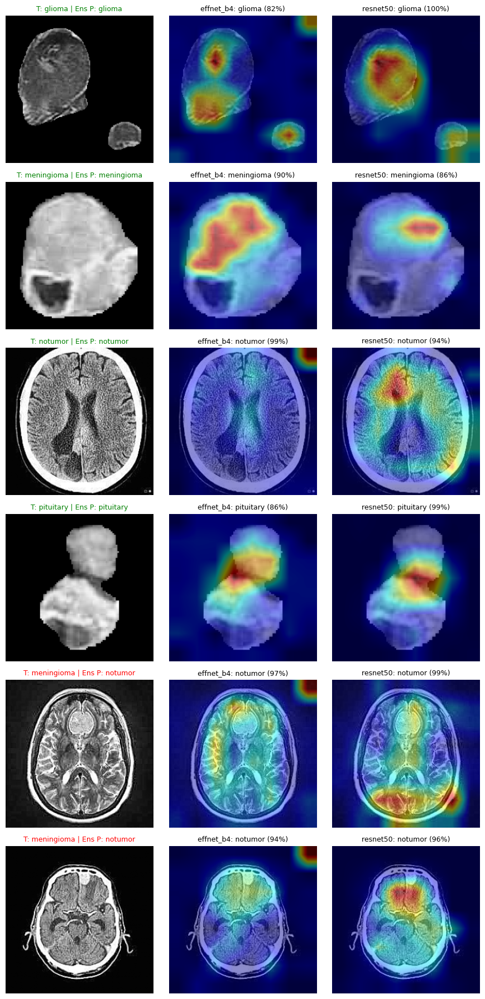

In [35]:
def gradcam(model, x, layer, target=None):
    acts, grads = {}, {}
    def fwd_hook(m, i, o):
        acts["a"] = o.detach(); o.register_hook(lambda g: grads.__setitem__("g", g.detach()))
    h = layer.register_forward_hook(fwd_hook)
    model.eval()
    for p in model.parameters(): p.requires_grad_(True)
    with torch.enable_grad():
        out = model(x); k = int(out.argmax(1)) if target is None else target
        model.zero_grad(); out[0, k].backward()
    h.remove()
    w = grads["g"].mean((2, 3), keepdim=True)
    cam = F.relu((w * acts["a"]).sum(1))[0].cpu().numpy()
    cam = cv2.resize(cam, (x.shape[3], x.shape[2])); cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return cam, k, F.softmax(out.detach().float(), 1)[0].cpu().numpy()

def overlay(roi, cam):
    heat = cv2.applyColorMap((cam * 255).astype(np.uint8), cv2.COLORMAP_JET)[..., ::-1]
    base = np.stack([roi] * 3, -1).astype(np.float32)
    return np.clip(0.55 * base + 0.45 * heat, 0, 255).astype(np.uint8)

# 1 contoh benar per kelas + 2 contoh salah (jika ada)
pick = [cls_te[(cls_te.label == c) & cls_te.correct].sample(1, random_state=SEED).iloc[0] for c in CLASSES]
pick += [r for _, r in cls_te[~cls_te.correct].sort_values("conf", ascending=False).head(2).iterrows()]
fig, ax = plt.subplots(len(pick), 3, figsize=(9, 3 * len(pick)), squeeze=False)
for r, row in enumerate(pick):
    roi = read_gray(row.roi); x = cls_preprocess(roi)
    ax[r, 0].imshow(roi, cmap="gray"); ax[r, 0].set_title(f"T: {row.label} | Ens P: {row.pred}", fontsize=9, color="green" if row.correct else "red")
    for c, (n, m) in enumerate(models.items(), start=1):
        cam, k, pr = gradcam(m, x.clone(), m.cam_layer())
        ax[r, c].imshow(overlay(roi, cam)); ax[r, c].set_title(f"{n}: {CLASSES[k]} ({pr[k]*100:.0f}%)", fontsize=9)
    for a in ax[r]: a.axis("off")
plt.tight_layout(); plt.show()

## Tahap 19 — End-to-End Inference (Ensemble) & Scan Dataset Lain

In [36]:
# @@SHARED:infer
@torch.no_grad()
def _probs(cls_model, x):
    cls_model.eval()
    with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
        out = cls_model(x)
    out = out.float()
    return out if isinstance(cls_model, EnsembleClassifier) else F.softmax(out, 1)

@torch.no_grad()
def predict_end_to_end(image_path, seg_model, cls_model, show=True):
    # Raw MRI -> segmentasi -> ROI -> klasifikasi (single model atau EnsembleClassifier)
    img  = read_gray(image_path)
    prob = predict_prob_batch(seg_model, [img])[0]
    roi, mask, bbox, fb = extract_roi(img, prob)
    p = _probs(cls_model, cls_preprocess(roi))[0].cpu().numpy(); k = int(p.argmax())
    res = dict(pred_class=CLASSES[k], confidence=float(p[k]), probs={c: round(float(v), 4) for c, v in zip(CLASSES, p)},
               tumor_detected=not fb, bbox=bbox)
    if show:
        fig, ax = plt.subplots(1, 4, figsize=(17, 4.2), gridspec_kw={"width_ratios": [1, 1, 1, 1.1]})
        ax[0].imshow(img, cmap="gray"); ax[0].set_title("Raw MRI")
        ax[1].imshow(img, cmap="gray"); ax[1].imshow(np.ma.masked_where(mask == 0, mask), cmap="autumn", alpha=.5)
        ax[1].add_patch(plt.Rectangle((bbox[0], bbox[1]), bbox[2]-bbox[0], bbox[3]-bbox[1], fill=False, ec="cyan", lw=2))
        ax[1].set_title("Predicted mask" + (" (kosong -> fallback)" if fb else ""))
        ax[2].imshow(roi, cmap="gray"); ax[2].set_title(f"ROI -> {res['pred_class']} ({res['confidence']*100:.1f}%)")
        for a in ax[:3]: a.axis("off")
        ax[3].barh(CLASSES, p, color=["tab:red" if i == k else "tab:gray" for i in range(len(CLASSES))]); ax[3].set_xlim(0, 1); ax[3].set_title("Probabilitas")
        plt.tight_layout(); plt.show()
    return res

@torch.no_grad()
def scan_folder(folder, seg_model, cls_model, out_csv=None, bs=32):
    # Scan seluruh folder (rekursif). Jika nama folder induk = nama kelas, akurasi dihitung otomatis.
    files = sorted(f for f in Path(folder).rglob("*") if f.suffix.lower() in IMG_EXT); rows = []
    for s in tqdm(range(0, len(files), bs)):
        chunk = files[s:s + bs]; imgs = [read_gray(f) for f in chunk]; rois, fbs, bbs = [], [], []
        for im, pr in zip(imgs, predict_prob_batch(seg_model, imgs)):
            roi, _, bb, fb = extract_roi(im, pr); rois.append(roi); fbs.append(fb); bbs.append(bb)
        x = torch.stack([EVAL_TF(Image.fromarray(r).convert("RGB")) for r in rois]).to(DEVICE)
        P = _probs(cls_model, x).cpu().numpy()
        for f, pi, fb, bb in zip(chunk, P, fbs, bbs):
            k = int(pi.argmax())
            rows.append(dict(file=str(f), parent=f.parent.name.lower(), pred=CLASSES[k], conf=float(pi[k]), tumor_detected=not fb,
                             bbox=bb, **{f"p_{c}": float(v) for c, v in zip(CLASSES, pi)}))
    df = pd.DataFrame(rows)
    if out_csv: df.to_csv(out_csv, index=False)
    known = df[df.parent.isin(CLASSES)] if len(df) else df
    if len(known): print(f"Akurasi (label dari nama folder, n={len(known)}): {(known.parent == known.pred).mean():.4f}")
    return df

True label: pituitary


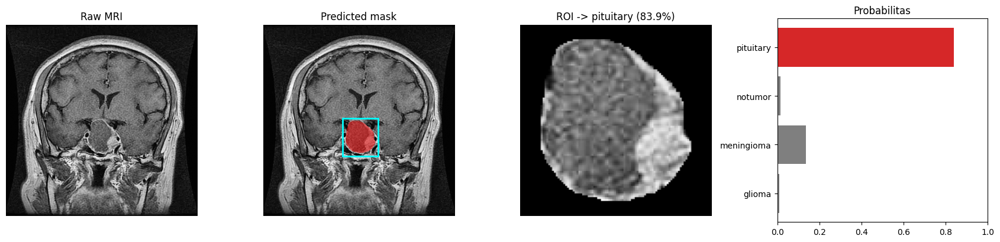

{'pred_class': 'pituitary', 'confidence': 0.8391029834747314, 'probs': {'glioma': 0.0099, 'meningioma': 0.1361, 'notumor': 0.0149, 'pituitary': 0.8391}, 'tumor_detected': True, 'bbox': (212, 250, 308, 352)}


In [37]:
sample = cls_te.sample(1, random_state=7).iloc[0]
print("True label:", sample.label)
print(predict_end_to_end(sample.image, seg_model, ensemble))

# ---- Scan dataset lain (belum bersegmentasi) ----
# scan_df = scan_folder("/kaggle/input/<dataset-lain>", seg_model, ensemble, out_csv=WORK_DIR / "scan_results.csv")
# print(scan_df.pred.value_counts()); scan_df.sort_values("conf").head(20)      # cek prediksi paling tidak yakin

## Tahap 20 — Simpan Artefak & Deployment Guide

In [38]:
ART = WORK_DIR / "artifacts"; ART.mkdir(exist_ok=True)

# 1) Bobot model
torch.save(seg_model.state_dict(), ART / "seg_model.pt")
torch.save(models["effnet_b4"].state_dict(), ART / "effnet_b4.pt")
torch.save(models["resnet50"].state_dict(),  ART / "resnet50.pt")

# 2) Config, metrik, histori, prediksi
cfg = dict(classes=CLASSES, seg_size=SEG_SIZE, cls_size=CLS_SIZE, seg_thr=SEG_THR, roi_margin=ROI_MARGIN, min_area=MIN_AREA,
           ensemble_weights=[W_EFF, W_RES], backbones=list(MODEL_CTORS), mean=MEAN, std=STD)
json.dump(cfg, open(ART / "config.json", "w"), indent=2)
metrics = dict(seg_test_dice=seg_test_dice, seg_test_iou=seg_test_iou, cls_test=summary.to_dict(), macro_auc=float(np.mean(aucs)))
json.dump(metrics, open(ART / "metrics.json", "w"), indent=2)
for n, h in hists.items(): h.to_csv(ART / f"history_{n}.csv", index=False)
if TRAIN_SEG: seg_hist.to_csv(ART / "history_seg.csv", index=False)
cls_te.drop(columns=["hash"], errors="ignore").to_csv(ART / "test_predictions.csv", index=False)

# 3) Script inferensi mandiri: dirakit dari sel bertanda # @@SHARED di notebook ini
ip = get_ipython(); src = {}
for cell in ip.user_ns["In"]:
    m = re.match(r"\s*# @@SHARED:(\w+)", cell)
    if m: src[m.group(1)] = cell                   # sel terbaru menimpa yang lama
need = ["consts", "arch", "roi", "cls", "infer"]
assert all(k in src for k in need), f"Sel SHARED belum dijalankan: {[k for k in need if k not in src]}"

IMPORTS = ("import os, re, json, argparse\nfrom pathlib import Path\nimport numpy as np, cv2, pandas as pd\n"
           "import matplotlib.pyplot as plt\nfrom PIL import Image\nimport torch, torch.nn as nn, torch.nn.functional as F\n"
           "import torchvision\nfrom torchvision import transforms as T\n"
           "try:\n    from tqdm.auto import tqdm\nexcept ImportError:\n    tqdm = lambda x, **k: x\n\n")
MAIN = r"""

def load_pipeline(art_dir="."):
    art = Path(art_dir)
    cfg = json.load(open(art / "config.json"))
    seg = AttentionUNet().to(DEVICE)
    seg.load_state_dict(torch.load(art / "seg_model.pt", map_location=DEVICE)); seg.eval()
    eff = EffNetB4Classifier(pretrained=False); eff.load_state_dict(torch.load(art / "effnet_b4.pt", map_location=DEVICE))
    res = ResNet50Classifier(pretrained=False); res.load_state_dict(torch.load(art / "resnet50.pt", map_location=DEVICE))
    ens = EnsembleClassifier([eff, res], cfg["ensemble_weights"]).to(DEVICE).eval()
    return seg, ens

if __name__ == "__main__":
    ap = argparse.ArgumentParser(description="Brain tumor two-stage CAD inference")
    ap.add_argument("path", help="file gambar MRI atau folder berisi gambar")
    ap.add_argument("--artifacts", default=".", help="folder berisi seg_model.pt, effnet_b4.pt, resnet50.pt, config.json")
    ap.add_argument("--csv", default=None, help="simpan hasil scan folder ke CSV")
    ap.add_argument("--show", action="store_true", help="tampilkan visualisasi (untuk 1 gambar)")
    a = ap.parse_args()
    seg, ens = load_pipeline(a.artifacts)
    p = Path(a.path)
    if p.is_dir():
        df = scan_folder(p, seg, ens, out_csv=a.csv); print(df.pred.value_counts())
    else:
        print(predict_end_to_end(p, seg, ens, show=a.show))
"""
(ART / "cad_inference.py").write_text(IMPORTS + "\n\n".join(src[k] for k in need) + "\n" + MAIN)

README = """# Brain Tumor Two-Stage CAD — Deployment Guide

Pipeline: Raw MRI -> Attention U-Net (mask) -> ROI crop -> EfficientNet-B4 + ResNet-50 ensemble -> kelas + confidence.

## File
- seg_model.pt, effnet_b4.pt, resnet50.pt : bobot (state_dict)
- config.json : kelas, ukuran input, threshold, bobot ensemble
- cad_inference.py : kode model + inferensi (mandiri, tidak butuh notebook)
- metrics.json, history_*.csv, test_predictions.csv : hasil evaluasi

## Install
pip install torch torchvision opencv-python-headless numpy pandas pillow matplotlib tqdm

## Pakai dari command line
python cad_inference.py path/ke/mri.jpg --artifacts . --show
python cad_inference.py path/ke/folder --artifacts . --csv hasil.csv

## Pakai dari Python
from cad_inference import load_pipeline, predict_end_to_end, scan_folder
seg, ens = load_pipeline("path/ke/artifacts")
print(predict_end_to_end("mri.jpg", seg, ens, show=False))
df = scan_folder("folder_mri", seg, ens, out_csv="hasil.csv")

## Catatan penting
- Input: citra MRI otak 2D (dibaca grayscale). Bukan untuk citra CT / modalitas lain.
- tumor_detected=False artinya mask kosong; ROI = citra penuh (fallback). Prediksi pada kasus ini kurang bisa dipercaya untuk kelas tumor.
- Cek prediksi dengan confidence rendah secara manual. Performa pada scanner/dataset berbeda bisa turun (domain shift).
- Alat riset/edukasi, BUKAN alat diagnosis klinis.
"""
(ART / "README_DEPLOY.md").write_text(README)

zip_path = shutil.make_archive(str(WORK_DIR / "cad_artifacts"), "zip", ART)
print("Artefak tersimpan di:", ART); print("ZIP:", zip_path); print(sorted(p.name for p in ART.iterdir()))

Artefak tersimpan di: /content/drive/MyDrive/final_project_dl/outputs_vbaru/artifacts
ZIP: /content/drive/MyDrive/final_project_dl/outputs_vbaru/cad_artifacts.zip
['README_DEPLOY.md', 'cad_inference.py', 'config.json', 'effnet_b4.pt', 'history_effnet_b4.csv', 'history_resnet50.csv', 'history_seg.csv', 'metrics.json', 'resnet50.pt', 'seg_model.pt', 'test_predictions.csv']
